# Lab 1A: Audio I/O and Understanding Audio Data

## Learning Objectives
- Read and write audio files using Python libraries
- Understand digital audio representation
- Extract and analyze basic audio properties
- Visualize audio waveforms

## Prerequisites
- Basic Python programming
- Understanding of arrays and numerical computation

## 1. Setup and Import Libraries

We'll use:
- **librosa**: Audio processing library
- **numpy**: Numerical computations
- **matplotlib**: Visualization
- **scipy**: Scientific computing (for writing audio files)

In [1]:
# Install required libraries (run only once)
# !pip install librosa numpy matplotlib scipy soundfile

import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")
print(f"Librosa version: {librosa.__version__}")

Libraries imported successfully!
Librosa version: 0.10.1


## 2. Reading Audio Files

### Digital Audio Representation
Audio is stored as a sequence of samples:
- **Sample Rate (sr)**: Number of samples per second (Hz)
- **Duration**: Length of audio in seconds
- **Amplitude**: Values representing sound pressure at each sample

In [2]:
# Specify your audio file path
audio_path = "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/XC710407-Warbler.mp3"  # CHANGE THIS to your audio file path

# Read audio file using librosa
# sr=None keeps the original sample rate
y, sr = librosa.load(audio_path, sr=None)

print("Audio loaded successfully!")
print(f"Sample Rate: {sr} Hz")
print(f"Audio Shape: {y.shape}")
print(f"Data Type: {y.dtype}")

Audio loaded successfully!
Sample Rate: 44100 Hz
Audio Shape: (209761,)
Data Type: float32


## 3. Understanding Audio Properties

Let's extract and understand key properties of the audio signal.

In [3]:
# Basic audio properties
num_samples = len(y)
duration = num_samples / sr  # Duration in seconds
num_channels = 1 if y.ndim == 1 else y.shape[0]  # Mono or stereo

# Amplitude statistics
max_amplitude = np.max(np.abs(y))
min_amplitude = np.min(y)
mean_amplitude = np.mean(y)

# Display properties
print("=" * 50)
print("AUDIO PROPERTIES")
print("=" * 50)
print(f"Duration: {duration:.2f} seconds")
print(f"Number of Samples: {num_samples:,}")
print(f"Sample Rate: {sr:,} Hz")
print(f"Number of Channels: {num_channels} (Mono)" if num_channels == 1 else f"Number of Channels: {num_channels} (Stereo)")
print(f"\nAmplitude Range: [{min_amplitude:.4f}, {max_amplitude:.4f}]")
print(f"Mean Amplitude: {mean_amplitude:.4f}")
print("=" * 50)

AUDIO PROPERTIES
Duration: 4.76 seconds
Number of Samples: 209,761
Sample Rate: 44,100 Hz
Number of Channels: 1 (Mono)

Amplitude Range: [-0.5421, 0.5556]
Mean Amplitude: -0.0000


### Think about!!!

**Q1:** Why is the sample rate important? What happens if we use a lower sample rate?

**Q2:** What does the amplitude range tell us about the audio signal?

**Q3:** If you have 2 seconds of audio at 44,100 Hz, how many samples do you have?

## 4. Visualizing Audio Waveform

Visualization helps us understand the audio signal's characteristics.

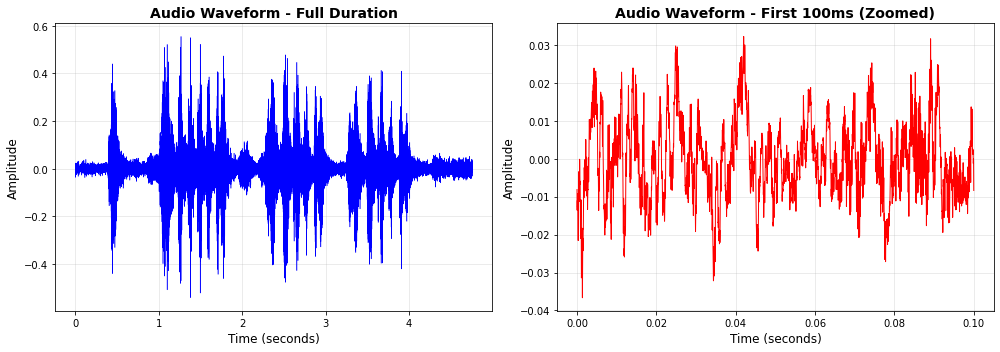

In [4]:
# Create time axis
time = np.linspace(0, duration, num_samples)

# Plot waveform
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(time, y, linewidth=0.5, color='blue')
plt.xlabel('Time (seconds)', fontsize=12)
plt.ylabel('Amplitude', fontsize=12)
plt.title('Audio Waveform - Full Duration', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Zoom in to first 0.1 seconds for detail
plt.subplot(1, 2, 2)
zoom_duration = min(0.1, duration)  # 100ms or full duration if shorter
zoom_samples = int(zoom_duration * sr)
time_zoom = time[:zoom_samples]
y_zoom = y[:zoom_samples]

plt.plot(time_zoom, y_zoom, linewidth=1, color='red')
plt.xlabel('Time (seconds)', fontsize=12)
plt.ylabel('Amplitude', fontsize=12)
plt.title(f'Audio Waveform - First {zoom_duration*1000:.0f}ms (Zoomed)', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

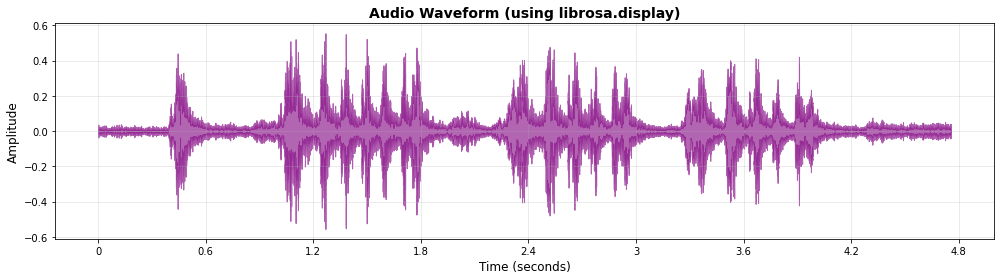

In [5]:
# Alternative: Using librosa's waveshow for better visualization
plt.figure(figsize=(14, 4))
librosa.display.waveshow(y, sr=sr, alpha=0.6, color='purple')
plt.xlabel('Time (seconds)', fontsize=12)
plt.ylabel('Amplitude', fontsize=12)
plt.title('Audio Waveform (using librosa.display)', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Understanding Sampling

Let's explore the relationship between time and samples.

In [6]:
# Calculate key timing information
sampling_period = 1 / sr  # Time between consecutive samples
nyquist_frequency = sr / 2  # Maximum frequency we can represent

print("SAMPLING INFORMATION")
print("=" * 50)
print(f"Sample Rate: {sr:,} Hz")
print(f"Sampling Period: {sampling_period*1000:.4f} milliseconds")
print(f"Nyquist Frequency: {nyquist_frequency:,} Hz")
print(f"\nInterpretation:")
print(f"- We capture {sr:,} samples every second")
print(f"- Each sample is {sampling_period*1000:.4f} ms apart")
print(f"- We can accurately represent frequencies up to {nyquist_frequency:,} Hz")
print("=" * 50)

SAMPLING INFORMATION
Sample Rate: 44,100 Hz
Sampling Period: 0.0227 milliseconds
Nyquist Frequency: 22,050.0 Hz

Interpretation:
- We capture 44,100 samples every second
- Each sample is 0.0227 ms apart
- We can accurately represent frequencies up to 22,050.0 Hz


### Think about!!!

**Q4:** Common sample rates are 8kHz (telephone), 16kHz (speech), 44.1kHz (CD), 48kHz (video). Why do we need higher sample rates for music than for speech?

**Q5:** What is the Nyquist frequency for CD-quality audio (44.1kHz)? Can we hear frequencies above this?

## 6. Audio Normalization

Normalization scales audio to a standard range, typically [-1, 1].

In [7]:
# Check if audio is already normalized
is_normalized = (np.max(np.abs(y)) <= 1.0)

print(f"Original max amplitude: {np.max(np.abs(y)):.4f}")
print(f"Is normalized? {is_normalized}")

# Normalize to [-1, 1] range
if not is_normalized:
    y_normalized = y / np.max(np.abs(y))
    print(f"\nAfter normalization:")
    print(f"Max amplitude: {np.max(np.abs(y_normalized)):.4f}")
else:
    y_normalized = y
    print("\nAudio is already normalized.")

Original max amplitude: 0.5556
Is normalized? True

Audio is already normalized.


## 7. Writing Audio Files

Save processed audio back to disk.

In [8]:
# Method 1: Using scipy (for WAV files)
output_path_scipy = "results/output_scipy.wav"

# scipy expects int16 format for WAV files
# Convert normalized float to int16 range [-32768, 32767]
y_int16 = np.int16(y_normalized * 32767)

wavfile.write(output_path_scipy, sr, y_int16)
print(f"Audio saved using scipy: {output_path_scipy}")

Audio saved using scipy: output_scipy.wav


In [9]:
# Method 2: Using soundfile (more flexible, supports multiple formats)
import soundfile as sf

output_path_sf = "results/output_soundfile.wav"

# soundfile can handle float directly (expects values in [-1, 1])
sf.write(output_path_sf, y_normalized, sr)
print(f"Audio saved using soundfile: {output_path_sf}")

Audio saved using soundfile: output_soundfile.wav


## 8. Stereo to Mono Conversion

If you have a stereo file, here's how to convert it to mono.

In [10]:
# Load audio as stereo (mono=False)
y_stereo, sr_stereo = librosa.load(audio_path, sr=None, mono=False)

print(f"Stereo audio shape: {y_stereo.shape}")

# If it's actually stereo (2 channels)
if y_stereo.ndim > 1 and y_stereo.shape[0] == 2:
    # Convert to mono by averaging channels
    y_mono = np.mean(y_stereo, axis=0)
    print(f"Converted to mono. Shape: {y_mono.shape}")
    
    # Or use librosa's built-in conversion
    y_mono_librosa, _ = librosa.load(audio_path, sr=None, mono=True)
    print(f"Librosa mono conversion. Shape: {y_mono_librosa.shape}")
else:
    print("Audio is already mono.")

Stereo audio shape: (209761,)
Audio is already mono.


## 9. Complete Audio Analysis Summary

Let's create a comprehensive summary function.

In [11]:
def analyze_audio(audio_path):
    """
    Comprehensive audio analysis function.
    
    Parameters:
    -----------
    audio_path : str
        Path to the audio file
    
    Returns:
    --------
    dict : Dictionary containing all audio properties
    """
    # Load audio
    y, sr = librosa.load(audio_path, sr=None)
    
    # Calculate properties
    properties = {
        'sample_rate': sr,
        'duration': len(y) / sr,
        'num_samples': len(y),
        'num_channels': 1 if y.ndim == 1 else y.shape[0],
        'max_amplitude': np.max(np.abs(y)),
        'min_amplitude': np.min(y),
        'mean_amplitude': np.mean(y),
        'std_amplitude': np.std(y),
        'is_normalized': np.max(np.abs(y)) <= 1.0,
        'nyquist_frequency': sr / 2,
        'sampling_period_ms': (1 / sr) * 1000
    }
    
    # Print summary
    print("\n" + "="*60)
    print("COMPLETE AUDIO ANALYSIS SUMMARY")
    print("="*60)
    print(f"File: {audio_path}")
    print(f"\nTIME DOMAIN:")
    print(f"  Duration: {properties['duration']:.3f} seconds")
    print(f"  Number of Samples: {properties['num_samples']:,}")
    print(f"  Sample Rate: {properties['sample_rate']:,} Hz")
    print(f"  Sampling Period: {properties['sampling_period_ms']:.4f} ms")
    print(f"\nCHANNEL INFO:")
    print(f"  Channels: {properties['num_channels']} ({'Mono' if properties['num_channels']==1 else 'Stereo'})")
    print(f"\nAMPLITUDE STATISTICS:")
    print(f"  Range: [{properties['min_amplitude']:.4f}, {properties['max_amplitude']:.4f}]")
    print(f"  Mean: {properties['mean_amplitude']:.4f}")
    print(f"  Std Dev: {properties['std_amplitude']:.4f}")
    print(f"  Normalized: {'Yes' if properties['is_normalized'] else 'No'}")
    print(f"\nFREQUENCY INFO:")
    print(f"  Nyquist Frequency: {properties['nyquist_frequency']:,} Hz")
    print(f"  Max Representable Frequency: {properties['nyquist_frequency']:,} Hz")
    print("="*60 + "\n")
    
    return properties, y, sr

# Use the function
audio_props, audio_data, sample_rate = analyze_audio(audio_path)


COMPLETE AUDIO ANALYSIS SUMMARY
File: /home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/XC710407-Warbler.mp3

TIME DOMAIN:
  Duration: 4.756 seconds
  Number of Samples: 209,761
  Sample Rate: 44,100 Hz
  Sampling Period: 0.0227 ms

CHANNEL INFO:
  Channels: 1 (Mono)

AMPLITUDE STATISTICS:
  Range: [-0.5421, 0.5556]
  Mean: -0.0000
  Std Dev: 0.0695
  Normalized: Yes

FREQUENCY INFO:
  Nyquist Frequency: 22,050.0 Hz
  Max Representable Frequency: 22,050.0 Hz



## Summary

In this lab, you learned:

1. **Audio I/O**: Read and write audio files using librosa, scipy, and soundfile
2. **Digital Audio**: Understanding sample rate, duration, and amplitude
3. **Sampling Theory**: Nyquist frequency and sampling period
4. **Visualization**: Plot waveforms to understand audio signals
5. **Normalization**: Scale audio to standard ranges
6. **Analysis**: Extract and interpret basic audio properties

### Key Takeaways:
- Sample rate determines the quality and frequency range of audio
- Nyquist frequency = Sample rate / 2 (maximum representable frequency)
- Normalization ensures consistent amplitude ranges
- Visualization helps understand signal characteristics
